In [ ]:
# Import required libraries
from pyspark.sql import SparkSession
from pyspark import StorageLevel
import time
import zipfile
import os
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import output
import statistics
from pyspark.sql import functions as F

In [ ]:
# create the spark session
spark = SparkSession.builder.appName("NYC_Taxi_Task4").getOrCreate()
# spark configuration and execution information
sc = spark.sparkContext

In [ ]:
# paths of ZIP files
TRAIN_ZIP = "/content/train_prepared.zip"
TEST_ZIP = "/content/test_prepared.zip"
# extract each ZIP into its own folder
with zipfile.ZipFile(TRAIN_ZIP, "r") as zip_ref:
    zip_ref.extractall("/content/train_prepared")
with zipfile.ZipFile(TEST_ZIP, "r") as zip_ref:
    zip_ref.extractall("/content/test_prepared")

In [ ]:
# loading preprocess data from Task 2
TRAIN_PATH = "/content/train_prepared"
TEST_PATH = "/content/test_prepared"
train_prepared = spark.read.parquet(TRAIN_PATH)
test_prepared = spark.read.parquet(TEST_PATH)

In [ ]:
print("Training rows:", train_prepared.count())
print("Testing rows:", test_prepared.count())
print("Training columns:", len(train_prepared.columns))
print("Testing columns:", len(test_prepared.columns))

Training rows: 2882775
Testing rows: 1234316
Training columns: 2
Testing columns: 2


In [ ]:
# checking current partition counts
train_partitions = train_prepared.rdd.getNumPartitions()
test_partitions = test_prepared.rdd.getNumPartitions()
print("Training partitions:", train_partitions)
print("Testing partitions:", test_partitions)

Training partitions: 7
Testing partitions: 7


In [ ]:
# inspect spark resource configuration
settings = [
    "spark.sql.shuffle.partitions",
    "spark.sql.adaptive.enabled"]
for setting in settings:
    try:
        value = spark.conf.get(setting)
    except Exception:
        value = "Not available"
    print(f"{setting}: {value}")
print("Default parallelism:", sc.defaultParallelism)
print("Spark version:", spark.version)
print("Spark UI URL:", sc.uiWebUrl)

spark.sql.shuffle.partitions: 200
spark.sql.adaptive.enabled: true
Default parallelism: 2
Spark version: 4.0.4
Spark UI URL: http://be0c41b704b7:4040


In [ ]:
output.serve_kernel_port_as_window(4040,path="/jobs/index.html")

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

Spark UI — jobs

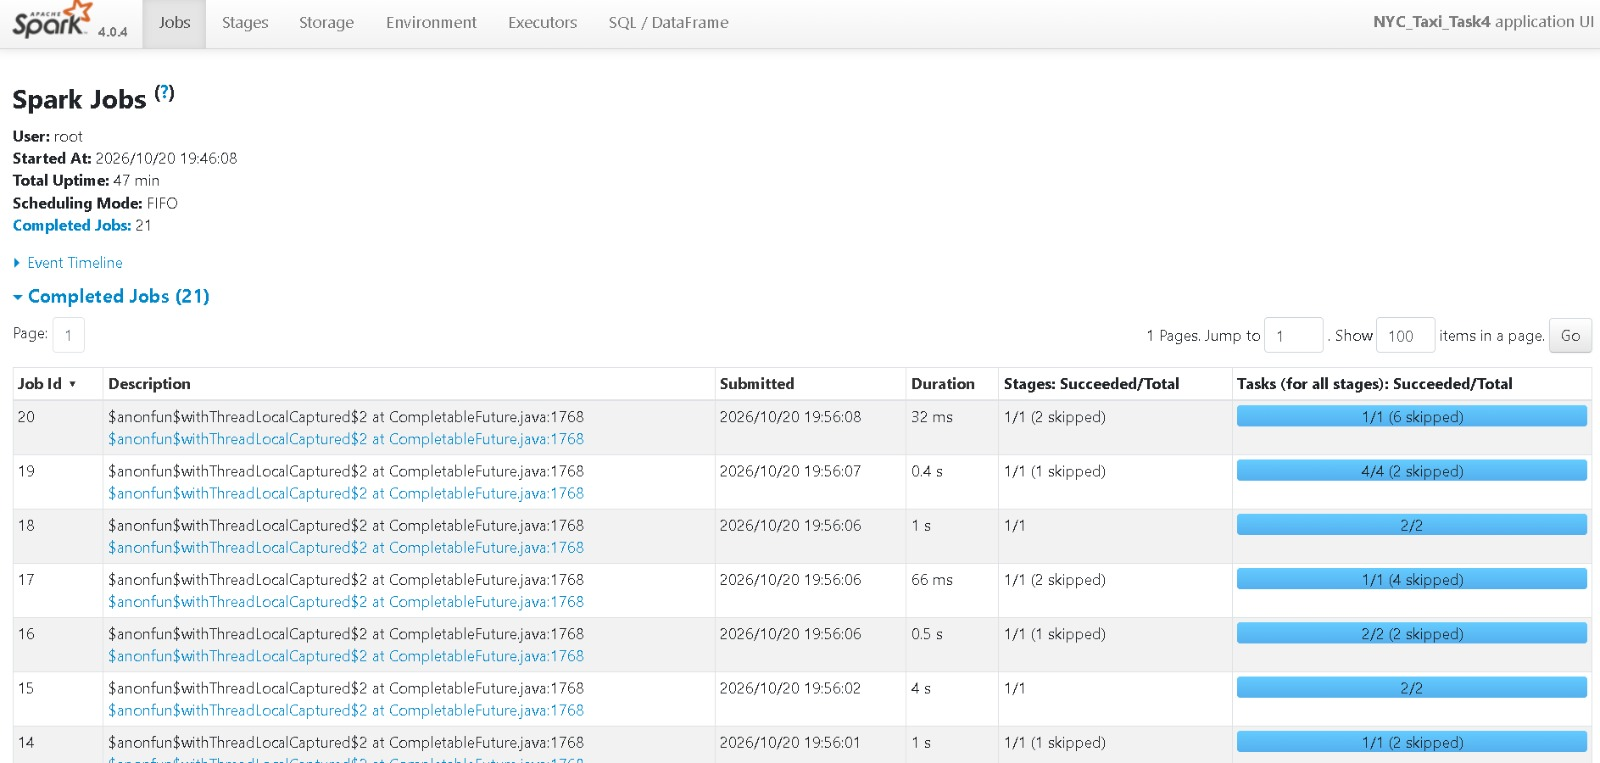

Spark UI — stages

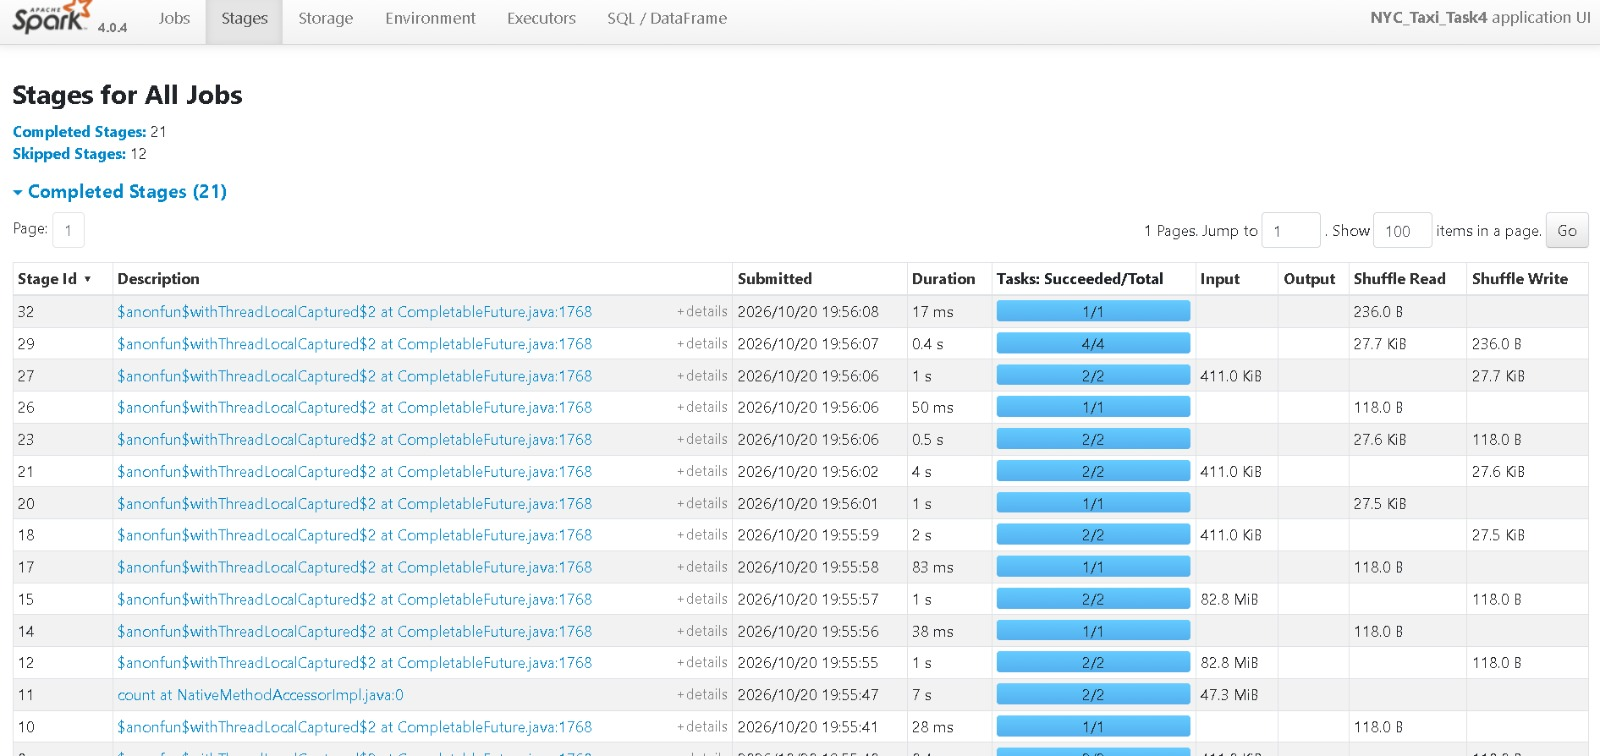

Spark UI — storage

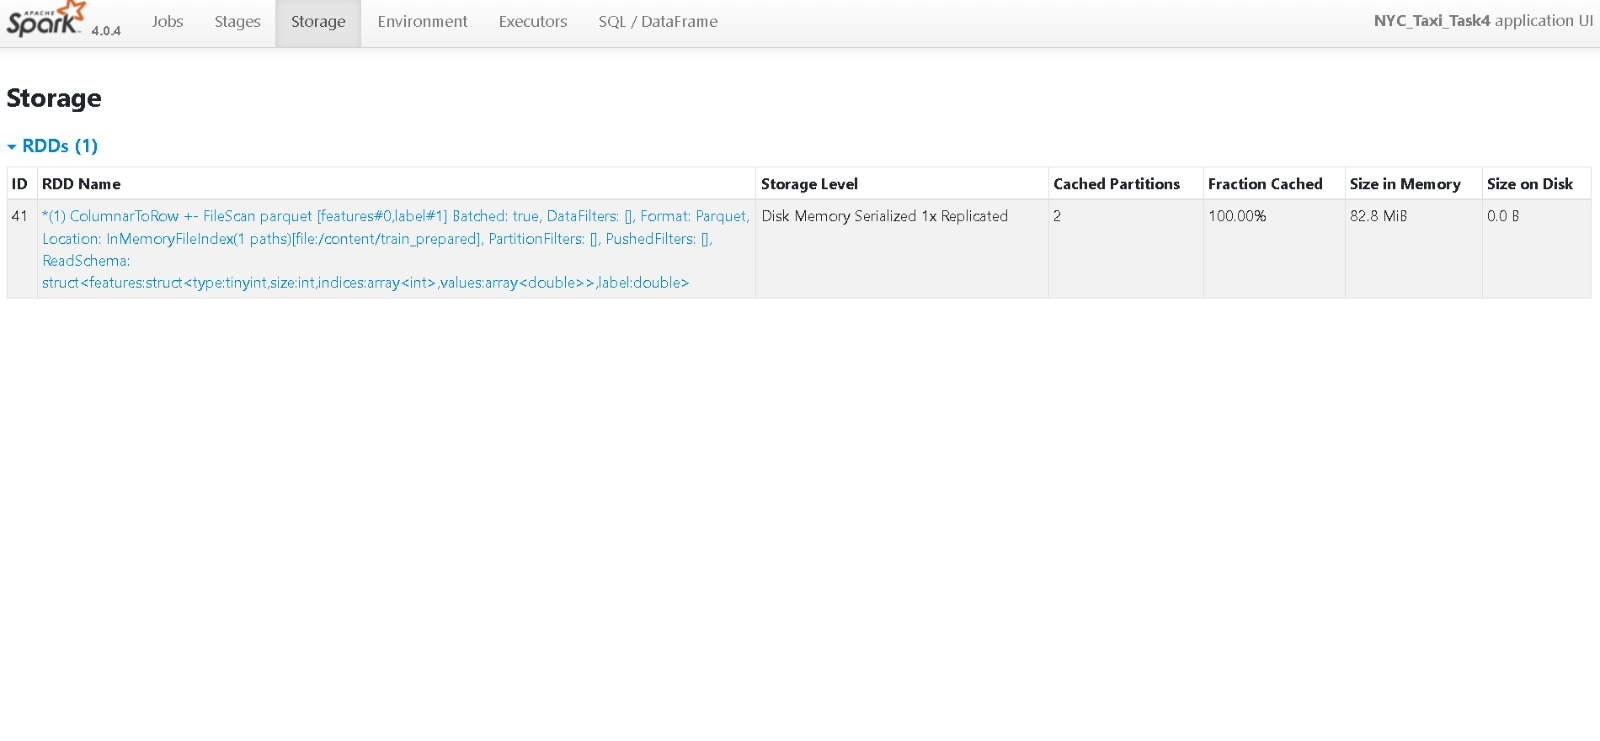

In [ ]:
 # measure baseline execution time
start_time = time.perf_counter()
row_count = train_prepared.count()
baseline_time = time.perf_counter() - start_time
print("Training rows:", row_count)
print("Baseline execution time:",round(baseline_time, 3),"seconds")

Training rows: 2882775
Baseline execution time: 1.294 seconds


In [ ]:
# persist the training DataFrame
train_cached = train_prepared.persist(StorageLevel.MEMORY_AND_DISK)


In [ ]:
# cache the training DataFrame using MEMORY_AND_DISK storage.
try:
    start_time = time.perf_counter() # First action: populate the cache
    row_count = train_cached.count()
    first_cached_time = time.perf_counter() - start_time
    print(f"First cached action: {first_cached_time:.3f} seconds")
    cached_times = [] # repeat the action three times
    for run_number in range(1, 4):
        start_time = time.perf_counter()
        train_cached.count()
        elapsed_time = time.perf_counter() - start_time
        cached_times.append(elapsed_time)
        print(
            f"Cached run {run_number}: "
            f"{elapsed_time:.3f} seconds")

    repeat_cached_time = statistics.median(cached_times) # Calculate median repeated execution time
    print("Repeated cached median:",round(repeat_cached_time, 3),"seconds")
    print("Repeated timings:",[round(t, 3) for t in cached_times])
    if repeat_cached_time > 0:
        cache_speedup = baseline_time / repeat_cached_time
        print(f"Measured cache speedup: {cache_speedup:.2f}x")
    else:
        cache_speedup = None
finally:
    train_cached.unpersist()

First cached action: 14.144 seconds
Cached run 1: 1.106 seconds
Cached run 2: 1.139 seconds
Cached run 3: 1.029 seconds
Repeated cached median: 1.106 seconds
Repeated timings: [1.106, 1.139, 1.029]
Measured cache speedup: 1.17x


In [ ]:
# Repartitioning strategy
current_partitions = train_prepared.rdd.getNumPartitions()
partition_options = sorted(set([max(1, current_partitions // 2),max(1, current_partitions),max(1, current_partitions * 2)]))
partition_results = []
for number in partition_options:
    run_times = []
    rows = None
    for run_number in range(1, 4):
        test_df = train_prepared.repartition(number)
        start_time = time.perf_counter()
        rows = test_df.count()
        elapsed_time = time.perf_counter() - start_time
        run_times.append(elapsed_time)
        print(
            f"Partitions: {number}, "
            f"Run: {run_number}, "
            f"Time: {elapsed_time:.3f} seconds")
    median_time = statistics.median(run_times)
    partition_results.append({
        "Partitions": number,
        "Rows": rows,
        "Median Time (sec)": round(median_time, 3),
        "Run 1 (sec)": round(run_times[0], 3),
        "Run 2 (sec)": round(run_times[1], 3),
        "Run 3 (sec)": round(run_times[2], 3)
    })
# Create the results table after testing every configuration
results_df = pd.DataFrame(partition_results)
# Compare each configuration with the current partition count
current_result = results_df[results_df["Partitions"] == current_partitions]
if not current_result.empty:
    current_median = float(
        current_result["Median Time (sec)"].iloc[0]
    )
    if current_median > 0:
        results_df["Speedup vs Current"] = (
            current_median / results_df["Median Time (sec)"]).round(2)
    else:
        results_df["Speedup vs Current"] = None
display(results_df)

Partitions: 3, Run: 1, Time: 2.831 seconds
Partitions: 3, Run: 2, Time: 2.567 seconds
Partitions: 3, Run: 3, Time: 3.135 seconds
Partitions: 7, Run: 1, Time: 2.036 seconds
Partitions: 7, Run: 2, Time: 1.758 seconds
Partitions: 7, Run: 3, Time: 2.090 seconds
Partitions: 14, Run: 1, Time: 1.957 seconds
Partitions: 14, Run: 2, Time: 1.802 seconds
Partitions: 14, Run: 3, Time: 2.561 seconds


,Partitions,Rows,Median Time (sec),Run 1 (sec),Run 2 (sec),Run 3 (sec),Speedup vs Current
0,3,2882775,2.831,2.831,2.567,3.135,0.72
1,7,2882775,2.036,2.036,1.758,2.090,1.00
2,14,2882775,1.957,1.957,1.802,2.561,1.04


In [ ]:
# compare every configuration with the current partition count.
current_result = results_df[results_df["Partitions"] == current_partitions]
if not current_result.empty:
    current_median = float(current_result["Median Time (sec)"].iloc[0])
    if current_median > 0:
        results_df["Speedup vs Current"] = (current_median / results_df["Median Time (sec)"]).round(2)
    else:
        results_df["Speedup vs Current"] = None
display(results_df)

,Partitions,Rows,Median Time (sec),Run 1 (sec),Run 2 (sec),Run 3 (sec),Speedup vs Current
0,3,2882775,2.831,2.831,2.567,3.135,0.72
1,7,2882775,2.036,2.036,1.758,2.090,1.00
2,14,2882775,1.957,1.957,1.802,2.561,1.04


In [ ]:
# files to export for the  dashboarding
config_df = pd.DataFrame([
    {
        "parameter": "spark.sql.shuffle.partitions",
        "value": spark.conf.get("spark.sql.shuffle.partitions")
    },
    {
        "parameter": "spark.sql.adaptive.enabled",
        "value": spark.conf.get("spark.sql.adaptive.enabled")
    },
    {
        "parameter": "default_parallelism",
        "value": sc.defaultParallelism
    },
    {
        "parameter": "spark_version",
        "value": spark.version
    }
])
display(config_df)

,parameter,value
0,spark.sql.shuffle.partitions,200
1,spark.sql.adaptive.enabled,true
2,default_parallelism,2
3,spark_version,4.0.4


CSV exported successfully.


In [ ]:
# Export cache benchmark results
cache_records = [{"experiment": "Baseline count","time_seconds": baseline_time},
    {"experiment": "First cached action","time_seconds": first_cached_time}]
for i, elapsed in enumerate(cached_times, start=1):
    cache_records.append({"experiment": f"Repeated cached run {i}","time_seconds": elapsed})
cache_records.append({"experiment": "Repeated cached median","time_seconds": repeat_cached_time})
cache_df = pd.DataFrame(cache_records)

In [ ]:
config_df.to_csv("/content/task4_spark_configuration.csv",index=False)
results_df.to_csv("/content/task4_partition_results.csv",index=False)
cache_df.to_csv("/content/task4_cache_results.csv",index=False)